# Spider-Verse Incident Dataset: Cleaning, EDA and a Baseline Model

**Goal:** analyse a deliberately messy dataset of Spider-Verse incidents. We clean it, explore it, prepare it for modelling and then train a simple baseline model that predicts an incident's **threat level**.

**Dataset source:** [Spiderman-dataset (Google Sheet)](https://docs.google.com/spreadsheets/d/1mvk2qKRA0Ol0pYCdj-fETSfNvWHAoPcErwWak9CIGsk/edit?gid=676581019) provided with the task.
**Libraries:** pandas, NumPy, Matplotlib, Seaborn, scikit-learn.
**Layout:** 1. Understanding, 2. Cleaning, 3. EDA, 4. Preprocessing, 5. Bonus baseline model, 6. Conclusions.

In [1]:
import re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)

## 1. Data understanding
We load the sheet as its CSV export. Everything is read as text first (`dtype=str`) so pandas does not silently hide bad values such as `?` or `ten`. If the online sheet is unreachable we fall back to the copy saved in this repo (`spiderman_raw.csv`).

In [2]:
SHEET = "https://docs.google.com/spreadsheets/d/1mvk2qKRA0Ol0pYCdj-fETSfNvWHAoPcErwWak9CIGsk/export?format=csv&gid=676581019"
try:
    raw = pd.read_csv(SHEET, dtype=str, keep_default_na=False)
except Exception:
    raw = pd.read_csv("spiderman_raw.csv", dtype=str, keep_default_na=False)

print("Shape (rows, columns):", raw.shape)
print("\nColumn names:", list(raw.columns))
raw.head(8)

Shape (rows, columns): (540, 10)

Column names: ['incident_id', 'universe', 'spider_person', 'villain', 'incident_type', 'city_damage_score', 'civilians_affected', 'anomaly_detected', 'response_time_min', 'threat_level']


,incident_id,universe,spider_person,villain,incident_type,city_damage_score,civilians_affected,anomaly_detected,response_time_min,threat_level
0,INC0421,Earth-928,Hobie Brown,Kingpin,Rescue,24.7,?,No,,Low
1,INC0182,Earth-928,Gwen Stacy,kingpin,Villain Sighting,57.5,NIL,Yes,23.4,Medium
2,INC0474,Earth-1610,pavitr prabhakar,Spot,,61.9,32,No,8.3,Medium
3,INC0330,Earth-1610,Miles Morales,Spot,Dimensional Anomaly,43.7,24,Yes,20.6,Medium
4,INC0174,,Peter Parker,Mysterio,Dimensional Anomaly,53.2,12,Yes,26,High
5,INC0073,EARTH-42,Hobie Brown,spot,,0,24,Yes,29.2,Low
6,INC0169,Earth-616,Miles Morales,Kingpin,Portal Instability,34.9,9999,Yes,22.8,Medium
7,INC0190,Earth-928,Pavitr Prabhakar,,Tech Theft,44.3,38,No,1.9,Low


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 540 entries, 0 to 539
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   incident_id         540 non-null    str  
 1   universe            540 non-null    str  
 2   spider_person       540 non-null    str  
 3   villain             540 non-null    str  
 4   incident_type       540 non-null    str  
 5   city_damage_score   540 non-null    str  
 6   civilians_affected  540 non-null    str  
 7   anomaly_detected    540 non-null    str  
 8   response_time_min   540 non-null    str  
 9   threat_level        540 non-null    str  
dtypes: str(10)
memory usage: 42.3 KB


**Shape and types.** The table has **540 rows and 10 columns**. Because we loaded everything as text, every column shows as `object`. The *intended* types are listed below.

| Column | Intended type | Meaning |
|---|---|---|
| `incident_id` | text (ID) | Unique id of the incident, e.g. `INC0421` |
| `universe` | categorical | Which Spider-Verse universe it happened in (Earth-616, Earth-928, ...) |
| `spider_person` | categorical | Which Spider-hero handled the incident |
| `villain` | categorical | The villain involved |
| `incident_type` | categorical | Kind of incident (Rescue, City Attack, Tech Theft, ...) |
| `city_damage_score` | numeric | Damage caused to the city (higher is worse) |
| `civilians_affected` | numeric (count) | Number of civilians affected |
| `anomaly_detected` | binary (Yes/No) | Whether a dimensional anomaly was detected |
| `response_time_min` | numeric | Minutes taken to respond |
| `threat_level` | ordinal (Low / Medium / High) | Assessed threat level, our **target** for modelling |

In [4]:
audit = pd.DataFrame({
    "unique_values": raw.nunique(),
    "blank_cells": (raw == "").sum(),
})
print("Fully duplicated rows:", raw.duplicated().sum())
print("Repeated incident_id :", raw["incident_id"].duplicated().sum())
audit

Fully duplicated rows: 26
Repeated incident_id : 40


,unique_values,blank_cells
incident_id,500,0
universe,26,20
spider_person,28,16
villain,31,41
incident_type,23,23
city_damage_score,314,32
civilians_affected,41,29
anomaly_detected,10,26
response_time_min,232,36
threat_level,10,13


In [5]:
print("universe has", raw["universe"].nunique(), "different spellings but should only have 5 real values:")
print(raw["universe"].value_counts().head(12).to_dict())

universe has 26 different spellings but should only have 5 real values:
{'Earth-928': 108, 'Earth-1610': 105, 'Earth-616': 83, 'Earth-42': 75, 'Earth-65': 70, '': 20, 'EARTH-42': 9, 'Earth 616': 7, 'EARTH-65': 7, 'Earth 928': 6, 'earth-616': 6, 'EARTH-928': 5}


**Problems spotted before cleaning**
- **Duplicates:** 26 fully duplicated rows, and 40 repeated `incident_id`s in total.
- **Inconsistent formats:** `universe` has 26 spellings of ~5 real values (`Earth-616`, `EARTH 616`, `E-616`). The same happens in the hero, villain, incident type, anomaly and threat columns (casing, extra spaces, aliases).
- **Wrong data types:** the numeric columns contain text such as `?`, `NIL`, `unknown`, `ten`, `85 points`, `35 people`, `12 min`.
- **Missing values:** blank cells in every column.
- **Outliers and impossible values:** sentinel codes like `999` and `9999`, and negative damage, counts and times.

## 2. Data cleaning
We work on a copy so the raw data stays untouched. Each step says what we found and why we chose the fix.

### 2.1 Duplicate rows
**Found:** exact duplicate rows and repeated `incident_id`s. **Fix: drop.** An incident id should be unique, so a second row is a data-entry duplicate. We keep the first row. Dropping them stops the same incident being counted twice in statistics and leaking into both the train and test sets later.

In [6]:
df = raw.copy()
before = len(df)
df = df.drop_duplicates()
print("After removing exact duplicates:", len(df), "rows (removed", before - len(df), ")")
df = df.drop_duplicates(subset="incident_id", keep="first").reset_index(drop=True)
print("After enforcing unique incident_id:", len(df), "rows")

After removing exact duplicates: 514 rows (removed 26 )
After enforcing unique incident_id: 500 rows


### 2.2 Inconsistent text formats (casing, spacing, aliases)
**Found:** the same value written many ways, for example `Hobie  Brown`, `HOBIE BROWN`, `Spider-Punk`, `E-42`, `Wilson Fisk`.
**Fix: convert.** We trim spaces, unify casing and map aliases to one canonical label so each real category is counted once. Alias choices (e.g. *Spider-Punk* = Hobie Brown, *Wilson Fisk* = Kingpin, *Doc Ock* = Doctor Octopus) are based on the comics. *"Spiderman"* alone is assumed to mean Peter Parker, which is a judgement call.
Blank or placeholder categorical values (`""`, `N/A`, `?`, `unknown`) become an explicit **`Unknown`** category, so we keep the row instead of throwing away its other information.

In [7]:
MISSING = {"", "?", "nil", "n/a", "unknown", "none", "nan"}

def tidy(v):
    return re.sub(r"\s+", " ", str(v)).strip()

def fix_text(col, mapping):
    def f(v):
        v = tidy(v)
        if v.lower() in MISSING:
            return "Unknown"
        if v.lower() in mapping:
            return mapping[v.lower()]
        return v.title() if (v.islower() or v.isupper()) else v
    df[col] = df[col].map(f)

# universe: keep the number, rebuild as 'Earth-<n>'
df["universe"] = df["universe"].map(
    lambda v: "Unknown" if not re.search(r"\d+", v) else "Earth-" + re.search(r"\d+", v).group())

fix_text("spider_person", {"spider-punk": "Hobie Brown", "spider-man (miles)": "Miles Morales",
    "spiderman": "Peter Parker", "spider-gwen": "Gwen Stacy", "miguel ohara": "Miguel O'Hara",
    "miguel o'hara": "Miguel O'Hara", "spider-man india": "Pavitr Prabhakar"})
fix_text("villain", {"the prowler": "Prowler", "wilson fisk": "Kingpin", "greengoblin": "Green Goblin",
    "the spot": "Spot", "doc ock": "Doctor Octopus", "doctor octopus": "Doctor Octopus",
    "quentin beck": "Mysterio", "green goblin": "Green Goblin"})
fix_text("incident_type", {"urban attack": "City Attack", "unstable portal": "Portal Instability",
    "technology theft": "Tech Theft", "villain spotted": "Villain Sighting",
    "civilian rescue": "Rescue", "dimension breach": "Dimensional Anomaly"})
fix_text("anomaly_detected", {"yes": "Yes", "y": "Yes", "no": "No", "n": "No", "nope": "No"})
fix_text("threat_level", {"moderate": "Medium", "minor": "Low", "low": "Low", "medium": "Medium", "high": "High"})

for c in ["universe", "spider_person", "villain", "incident_type", "anomaly_detected", "threat_level"]:
    print(f"{c:17s}", df[c].value_counts().to_dict())

universe          {'Earth-928': 118, 'Earth-1610': 105, 'Earth-616': 94, 'Earth-42': 90, 'Earth-65': 76, 'Unknown': 17}
spider_person     {"Miguel O'Hara": 87, 'Gwen Stacy': 84, 'Miles Morales': 84, 'Hobie Brown': 83, 'Pavitr Prabhakar': 77, 'Peter Parker': 70, 'Unknown': 15}
villain           {'Unknown': 96, 'Mysterio': 72, 'Spot': 59, 'Prowler': 58, 'Green Goblin': 57, 'Doctor Octopus': 57, 'Kingpin': 53, 'Venom': 48}
incident_type     {'Dimensional Anomaly': 92, 'City Attack': 92, 'Tech Theft': 80, 'Rescue': 74, 'Villain Sighting': 71, 'Portal Instability': 71, 'Unknown': 20}
anomaly_detected  {'No': 241, 'Yes': 234, 'Unknown': 25}
threat_level      {'Low': 245, 'Medium': 228, 'High': 15, 'Unknown': 12}


**Result:** `universe` went from 26 spellings to 5 real universes (+ Unknown), and every categorical column now has only its true categories. `threat_level` has the three real levels.

### 2.3 Wrong data types in numeric columns
**Found:** `city_damage_score`, `civilians_affected` and `response_time_min` are text because they contain `ten`, `twenty`, `seventy`, `85 points`, `35 people`, `12 min`, `?`, `NIL`, `N/A`, `unknown`.
**Fix: convert.** Number words become digits, units are stripped (`85 points` becomes `85`), and placeholders such as `?`/`NIL`/`unknown` become real missing values (`NaN`). We convert rather than drop because these rows contain valid information in their other columns.

In [8]:
WORDS = {"ten": 10, "twenty": 20, "seventy": 70}
NUM = ["city_damage_score", "civilians_affected", "response_time_min"]

def to_num(v):
    v = tidy(v).lower()
    if v in MISSING:
        return np.nan
    if v in WORDS:
        return WORDS[v]
    m = re.search(r"-?\d+(\.\d+)?", v)
    return float(m.group()) if m else np.nan

for c in NUM:
    df[c] = df[c].map(to_num)

df[NUM].describe().round(1)

,city_damage_score,civilians_affected,response_time_min
count,459.0,466.0,455.0
mean,36.0,118.3,20.6
std,92.3,927.5,58.0
min,-20.0,-10.0,-7.0
25%,14.3,24.0,8.3
50%,27.3,28.0,14.5
75%,39.7,31.0,23.7
max,999.0,9999.0,999.0


### 2.4 Impossible values and outliers
**Found:** the `max` row above shows `999` and `9999`, and `min` shows negative values. A negative damage score, civilian count or response time is impossible, and `9999` civilians or `999` minutes are placeholder or typo codes (the normal values sit around 25 to 30 civilians and 15 minutes).
**Fix:**
1. **Negatives to missing** (they cannot be real).
2. **Extreme outliers to missing** using a deliberately generous rule, anything above `Q3 + 3 x IQR`. We do not use the usual 1.5 x IQR, because that would also delete genuinely high but real values. Setting them to missing (instead of *capping*) is better here, because the values look like error codes rather than real extremes, so capping them at a boundary would invent data.

In [9]:
print("Negative values:", {c: int((df[c] < 0).sum()) for c in NUM})
for c in NUM:
    df.loc[df[c] < 0, c] = np.nan

for c in NUM:
    q1, q3 = df[c].quantile([.25, .75])
    upper = q3 + 3 * (q3 - q1)
    bad = df[c] > upper
    print(f"{c:20s} upper limit {upper:7.1f} | outliers removed: {int(bad.sum())} -> {sorted(df.loc[bad, c].unique())}")
    df.loc[bad, c] = np.nan

Negative values: {'city_damage_score': 4, 'civilians_affected': 4, 'response_time_min': 4}
city_damage_score    upper limit   114.1 | outliers removed: 5 -> [np.float64(130.0), np.float64(999.0)]
civilians_affected   upper limit    52.0 | outliers removed: 5 -> [np.float64(2500.0), np.float64(9999.0)]
response_time_min    upper limit    69.6 | outliers removed: 6 -> [np.float64(99.0), np.float64(250.0), np.float64(500.0), np.float64(999.0)]


### 2.5 Missing values
**Found:** about 9 to 11% of each numeric column is now missing (43 to 55 of 500 values) (blanks, placeholders, negatives, outliers).
**Fix: impute with the median.** The data is right-skewed (a few big values), so the median is more robust than the mean. We do not drop these rows, since that would lose roughly a quarter of the incidents. The categorical blanks were already handled as `Unknown` in step 2.2.

In [10]:
print("Missing before imputation:\n", df[NUM].isna().sum().to_string())
for c in NUM:
    df[c] = df[c].fillna(df[c].median())
print("\nMissing after imputation:", int(df[NUM].isna().sum().sum()))
print("Final shape:", df.shape)
df[NUM].describe().round(1)

Missing before imputation:
 city_damage_score     50
civilians_affected    43
response_time_min     55

Missing after imputation: 0
Final shape: (500, 10)


,city_damage_score,civilians_affected,response_time_min
count,500.0,500.0,500.0
mean,27.6,27.7,15.5
std,16.7,5.1,8.2
min,0.0,12.0,1.0
25%,15.8,24.0,8.8
50%,27.2,28.0,14.4
75%,38.0,31.0,22.5
max,85.0,49.0,37.4


**Cleaning summary:** 540 rows reduced to **500 unique incidents**. Categories are consistent, the numeric columns are numeric, and the impossible values and outliers are gone. The ranges now look sensible: damage 0 to 85, civilians 12 to 49, response time 1 to 37 minutes.

## 3. Exploratory data analysis (EDA)

In [11]:
df[NUM].describe().round(2)

,city_damage_score,civilians_affected,response_time_min
count,500.00,500.00,500.00
mean,27.65,27.75,15.47
std,16.66,5.07,8.23
min,0.00,12.00,1.00
25%,15.80,24.00,8.80
50%,27.25,28.00,14.40
75%,37.95,31.00,22.50
max,85.00,49.00,37.40


In [12]:
df.describe(include="object").T

,count,unique,top,freq
incident_id,500,500,INC0421,1
universe,500,6,Earth-928,118
spider_person,500,7,Miguel O'Hara,87
villain,500,8,Unknown,96
incident_type,500,7,Dimensional Anomaly,92
anomaly_detected,500,3,No,241
threat_level,500,4,Low,245


**Summary statistics.** A typical incident has about 28 civilians affected (mean 27.7, std 5.1, so very consistent), a damage score around 27 (std 16.7, much more spread out) and a response time around 14 to 15 minutes. Mean damage 27.6 is close to the median 27.2, so the cleaned distribution is roughly symmetric. About 23 incidents have a damage score of exactly 0, which could be genuine "no damage" rescues or default entries.

### Graph 1: Distribution of the target, threat level

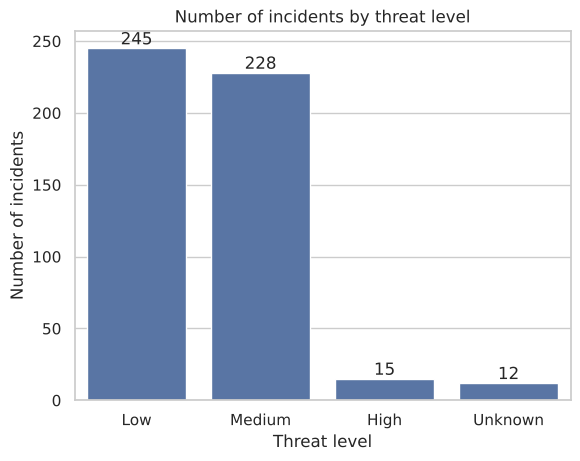

In [13]:
order = ["Low", "Medium", "High", "Unknown"]
ax = sns.countplot(data=df, x="threat_level", order=order)
ax.bar_label(ax.containers[0])
plt.title("Number of incidents by threat level")
plt.xlabel("Threat level"); plt.ylabel("Number of incidents")
plt.show()

**Interpretation:** The classes are heavily **imbalanced**: Low (245) and Medium (228) dominate, while High is rare (only 15 incidents, 3%). Any model will find High hard to learn, and plain accuracy will look flattering.

### Graph 2: Incident types

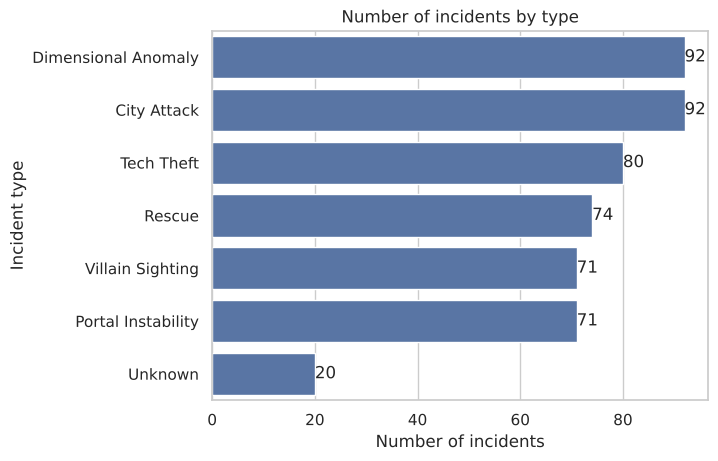

In [14]:
ax = sns.countplot(data=df, y="incident_type", order=df["incident_type"].value_counts().index)
ax.bar_label(ax.containers[0])
plt.title("Number of incidents by type")
plt.xlabel("Number of incidents"); plt.ylabel("Incident type")
plt.show()

**Interpretation:** The six real incident types are evenly spread (71 to 92 incidents each), with Dimensional Anomaly and City Attack the most common. Only 20 incidents have an unknown type, so type information is mostly reliable.

### Graph 3: Distribution of city damage

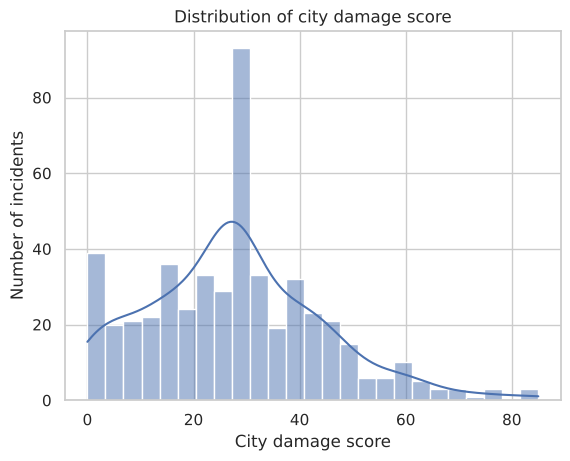

In [15]:
sns.histplot(df["city_damage_score"], bins=25, kde=True)
plt.title("Distribution of city damage score")
plt.xlabel("City damage score"); plt.ylabel("Number of incidents")
plt.show()

**Interpretation:** Damage is bell-shaped and centred near 27, with a tail towards higher values up to 85. The spike at 0 comes from incidents with no recorded damage.

### Graph 4: Damage by threat level

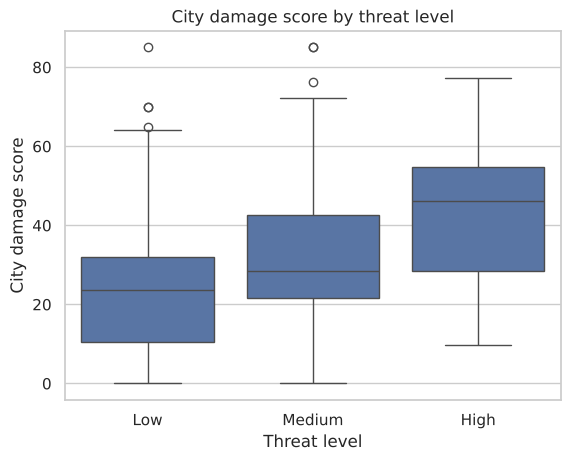

threat_level
High      43.8
Low       22.7
Medium    32.1
Name: city_damage_score, dtype: float64

In [16]:
sns.boxplot(data=df[df.threat_level != "Unknown"], x="threat_level", y="city_damage_score", order=["Low", "Medium", "High"])
plt.title("City damage score by threat level")
plt.xlabel("Threat level"); plt.ylabel("City damage score")
plt.show()
df[df.threat_level != "Unknown"].groupby("threat_level")["city_damage_score"].mean().round(1)

**Interpretation:** Damage rises with threat level: the average is about **23 for Low, 32 for Medium and 44 for High**. Damage is therefore a useful signal of threat level, although the boxes overlap, so it cannot separate the levels on its own.

### Graph 5: Response time vs anomaly detection

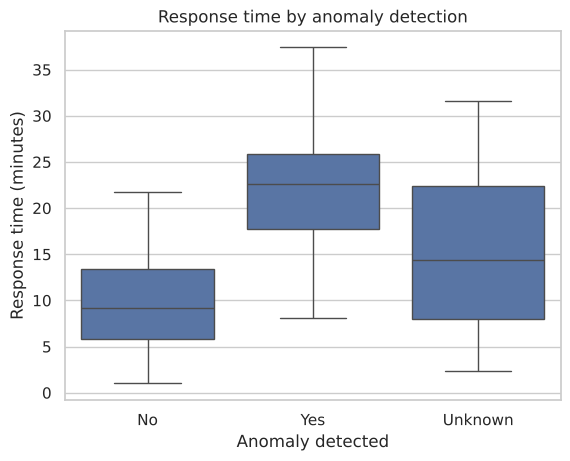

anomaly_detected
No          9.3
Unknown    15.3
Yes        21.9
Name: response_time_min, dtype: float64

In [17]:
sns.boxplot(data=df, x="anomaly_detected", y="response_time_min", order=["No", "Yes", "Unknown"])
plt.title("Response time by anomaly detection")
plt.xlabel("Anomaly detected"); plt.ylabel("Response time (minutes)")
plt.show()
df.groupby("anomaly_detected")["response_time_min"].mean().round(1)

**Interpretation:** This is the clearest relationship in the data. When an anomaly is detected, the average response time is about **22 minutes, against about 9 minutes** when there is none. Responding to dimensional trouble takes much longer, which also explains why Dimensional Anomaly and Portal Instability incidents have the slowest responses.

### Graph 6: Correlation heatmap of numeric features

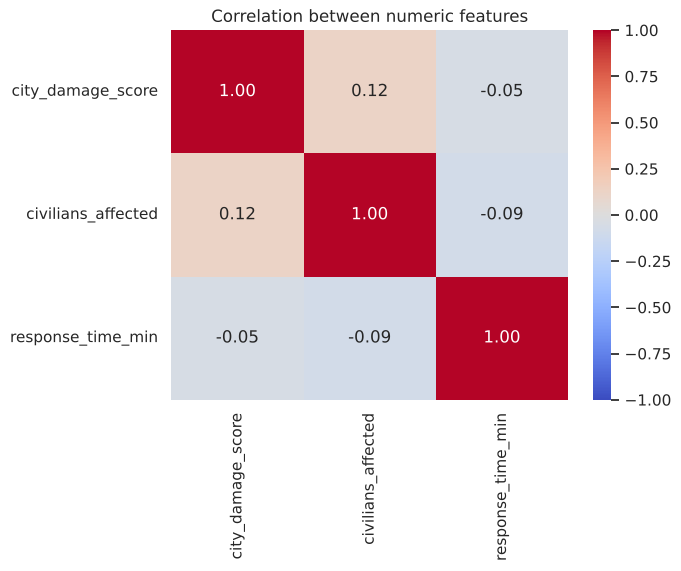

In [18]:
sns.heatmap(df[NUM].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numeric features")
plt.show()

**Interpretation:** All correlations between the three numeric columns are **very weak** (the largest is 0.12, between damage and civilians affected). So the numeric columns carry mostly independent information and there is no multicollinearity problem. It also means the strong patterns must come from the categorical columns (anomaly, incident type) rather than from the numbers alone.

### Graph 7: Threat level mix by incident type

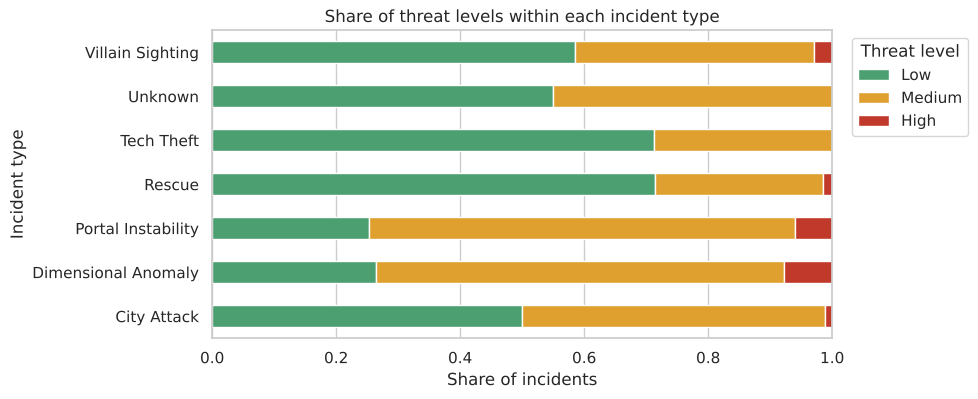

In [19]:
known = df[df.threat_level != "Unknown"]
mix = pd.crosstab(known["incident_type"], known["threat_level"], normalize="index")[["Low", "Medium", "High"]]
mix.plot(kind="barh", stacked=True, color=["#4c9f70", "#e0a030", "#c0392b"], figsize=(8, 4))
plt.title("Share of threat levels within each incident type")
plt.xlabel("Share of incidents"); plt.ylabel("Incident type")
plt.legend(title="Threat level", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Interpretation:** Threat depends strongly on incident type. **Dimensional Anomaly and Portal Instability** are mostly Medium (66 to 69%) and are the only types with a noticeable High share (6 to 8%). **Rescue and Tech Theft** are about 71% Low. The incident type is clearly informative for predicting threat.

### Graph 8: Villains

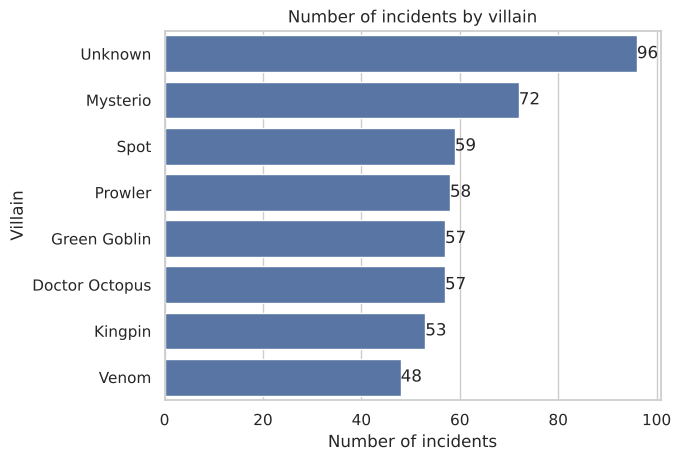

In [20]:
ax = sns.countplot(data=df, y="villain", order=df["villain"].value_counts().index)
ax.bar_label(ax.containers[0])
plt.title("Number of incidents by villain")
plt.xlabel("Number of incidents"); plt.ylabel("Villain")
plt.show()

**Interpretation:** Mysterio appears most (72 incidents), and the other six named villains each appear 48 to 59 times. The largest group is `Unknown` (96), roughly a fifth of all incidents, so the villain column has limited reliability.

### EDA observations (in plain words)
1. **Threat level is imbalanced:** about 97% of labelled incidents are Low or Medium, and High is only 3%.
2. **Anomalies slow responses:** incidents with a detected anomaly take about 22 minutes to respond to, versus about 9 without one.
3. **Damage and threat go together:** the average damage score is about 23, 32 and 44 for Low, Medium and High threat.
4. **Incident type predicts threat:** dimensional and portal incidents are mostly Medium or High, while rescues and tech thefts are mostly Low.
5. **Numeric features are nearly uncorrelated** (all |r| below 0.13), so the signal for threat is spread across several different features.

## 4. Preprocessing
The dataset has a target (`threat_level`), so we prepare it for supervised learning:
- **Rows with an unknown target** (12 incidents) are removed from modelling because we cannot train or score on a missing label.
- **Categorical features** are one-hot encoded (no natural order between heroes, villains and universes).
- **Numeric features** are standardised (mean 0, std 1) so that a column with large values does not dominate.
- **Train/test split:** 80/20, *stratified* on the target so the rare High class appears in both parts, with a fixed seed for repeatability.
- The encoders and scaler are fitted on the training data only (inside a pipeline), so no information leaks from the test set.

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

CAT = ["universe", "spider_person", "villain", "incident_type", "anomaly_detected"]
model_df = df[df["threat_level"] != "Unknown"]
X, y = model_df[CAT + NUM], model_df["threat_level"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
    ("num", StandardScaler(), NUM),
])
Xt = preprocess.fit_transform(X_train)
print("Rows used for modelling:", len(model_df))
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Encoded training matrix:", Xt.shape)
print("\nTarget share in train:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Target share in test :", y_test.value_counts(normalize=True).round(3).to_dict())

Rows used for modelling: 488
Train: (390, 8)  Test: (98, 8)
Encoded training matrix: (390, 34)

Target share in train: {'Low': 0.503, 'Medium': 0.467, 'High': 0.031}
Target share in test : {'Low': 0.5, 'Medium': 0.469, 'High': 0.031}


## 5. Bonus: baseline model
We train a simple, explainable **logistic regression** to predict `threat_level`. To judge whether it learned anything, we compare it with a **dummy baseline** that always predicts the most common class. Because the classes are imbalanced, we report both **accuracy** and **macro F1** (the average F1 over classes, which treats rare High as equally important).

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

models = {
    "Baseline (always most common class)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000),
}
results = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)]).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results[name] = (accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro"))
    if name == "Logistic regression":
        best_pipe, best_pred = pipe, pred

pd.DataFrame(results, index=["Accuracy", "Macro F1"]).T.round(3)

,Accuracy,Macro F1
Baseline (always most common class),0.500,0.222
Logistic regression,0.776,0.741


              precision    recall  f1-score   support

        High       0.67      0.67      0.67         3
         Low       0.78      0.82      0.80        49
      Medium       0.77      0.74      0.76        46

    accuracy                           0.78        98
   macro avg       0.74      0.74      0.74        98
weighted avg       0.78      0.78      0.78        98



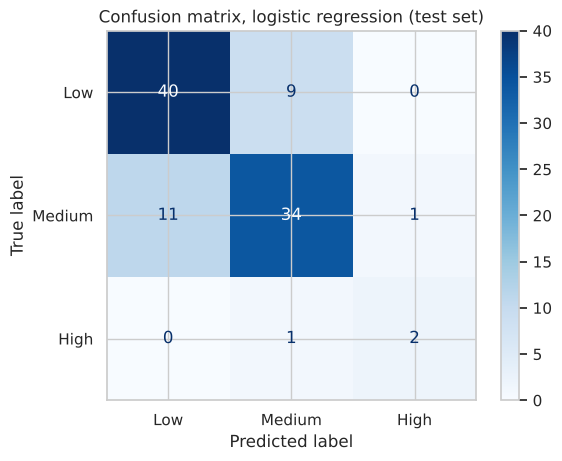

In [23]:
print(classification_report(y_test, best_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, labels=["Low", "Medium", "High"], cmap="Blues")
plt.title("Confusion matrix, logistic regression (test set)")
plt.show()

**What the results tell us**
- The always-predict-the-majority baseline scores about **50% accuracy** (and a macro F1 of only 0.22), because it never predicts Medium or High.
- The logistic regression reaches about **78% accuracy and a macro F1 of 0.74**, so the features (anomaly, incident type, damage, response time) clearly contain real signal about the threat level.
- Low and Medium are predicted fairly well (F1 about 0.80 and 0.76). The confusion matrix shows most mistakes are between neighbouring levels (Low vs Medium), which is understandable.
- **Caution:** the test set holds only **3 High incidents**, so the High result (2 of 3 found) is far too small a sample to trust. Collecting more High-threat cases would be the main way to improve the model.
- This is a baseline. Possible next steps: a tree-based model, cross-validation, class weighting and the engineered features suggested below.

## 6. Conclusions
- **Data quality:** the raw sheet had 40 duplicate incidents, 26 spellings of 5 universes, text inside numeric columns, impossible negative values and sentinel outliers (`999`, `9999`). After cleaning we have **500 unique, consistent incidents**.
- **Main findings:** an anomaly slows the response time (about 22 vs 9 minutes), higher damage goes with higher threat, and incident type is strongly tied to threat level.
- **Model:** a simple logistic regression predicts threat level with about 78% accuracy versus a 50% baseline, but the rare High class is too small to evaluate reliably.
- **Assumptions to be aware of:** alias mapping (e.g. "Spiderman" = Peter Parker), median imputation, treating very extreme values as errors, and dropping 12 rows with no threat label for modelling.